### Semi-Autonomous Agentic Workflows Project

### Name: Sayed Saidoo

### Project Overview

**Restaurant Inventory Operations Agentic System**

This project implements a semi-autonomous multi-agent system designed to support restaurant inventory management, supplier planning, and food waste reduction. The system receives natural language sales reports from restaurant staff, converts them into structured sales data, updates inventory records, analyzes inventory health, and generates operational recommendations for restaurant managers.

The project models a small Italian restaurant serving a limited menu of pizzas and pasta dishes. `A Sales Intake Agent` extracts structured sales information from staff reports and passes it to an `Inventory Orchestrator Agent`, which manages workflow state and coordinates all agent interactions throughout the session.

The orchestrator delegates inventory-related tasks to an `Inventory Operations Agent`, which uses database tools and recipe information to calculate ingredient consumption, update inventory levels, and assess inventory health. Based on the inventory assessment returned by this agent, the orchestrator determines the next workflow step.

If inventory remains healthy, the orchestrator generates a summary of the current inventory state and terminates the workflow. If inventory risks are detected, the orchestrator invokes two specialized agents:

- A `Reorder Agent`, which evaluates stock shortages, compares supplier pricing, and generates replenishment recommendations.
- A `Menu Strategy` Agent, which proposes profitable menu specials that help utilize existing inventory and reduce potential waste.

The recommendations produced by these agents are reviewed by an `Operations Critic Agent`, which validates profitability, inventory feasibility, and overall alignment with restaurant objectives. Approved recommendations are then presented to a restaurant manager for final review.

Following manager approval, the `Inventory Orchestrator Agent` invokes the `Inventory Operations Agent` to execute the approved database updates, including inventory replenishment and menu updates. The orchestrator then summarizes the final operational state and closes the workflow. If recommendations are rejected by management, the orchestrator routes the workflow through a retry path, allowing recommendations to be regenerated before a final approval decision is made.

The system combines:

- Gemini Flash for agent reasoning
- Pydantic models for structured communication between agents
- SQLite for persistent operational state
- Custom business tools for inventory calculations, vendor comparisons, profitability analysis, and database updates
- A custom state-machine orchestrator that manages workflow transitions, routing decisions, and session state

**The primary objective of the system is to assist restaurant managers in making informed operational decisions while maintaining human oversight.** The workflow demonstrates key agentic AI concepts including multi-agent orchestration, session state management, tool use, conditional routing, parallel task execution, reflection and critique loops, database interaction, and human-in-the-loop decision making.

### Agent Architecture and Workflow Design

#### Architecture Overview

The workflow is coordinated by an Inventory Orchestrator Agent, which maintains session state and determines which specialized agents should be invoked throughout the workflow.

**Sales Intake Agent**

Role: Convert natural language sales reports into structured sales data.

Responsibilities:

- Extract menu items and quantities from natural-language sales reports
- Convert unstructured input into validated Pydantic models

**Inventory Orchestrator Agent**

Role: Central workflow coordinator.

Responsibilities:

- Maintain session state
- Route requests to specialized agents
- Manage workflow transitions
- Consolidate results
- Generate final summaries

**Inventory Operations Agent**

Role: Inventory and database specialist.

Responsibilities:

- Calculate ingredient consumption
- Update inventory records
- Assess inventory health
- Execute approved database updates
- Generate inventory assessments used by downstream agents


Tools:

- Inventory Updates (menu, inventory items)
- Recipe lookup functions
- Inventory threshold/health checks

**Reorder Agent**

Role: Procurement specialist.

Responsibilities:

- Identify replenishment needs
- Balance delivery speed, stock-out risk, and supplier costs
- Recommend vendors and quantities

Tools:

- Vendor pricing query
- Low stock query
- Reorder quantity

**Menu Strategy Agent**

Role: Menu optimization specialist.

Responsibilities:

- Generate menu specials
- Improve ingredient utilization
- Reduce food waste

Tools:

- Inventory expiry checks

**Operations Critic Agent**

Role: Validation and reflection layer.

Responsibilities:

- Validate recommendations
- Evaluate operational feasibility
- Review inventory and procurement decisions
- Provide approval recommendations and confidence scores


**Memory and State Design**

No multi turn memory required as this is a single workflow system.

The Inventory Orchestrator maintains workflow state through a shared WorkflowState object. Agents read and update only the information relevant to their responsibilities, allowing the workflow to remain modular and loosely coupled.

**Persistent Memory**

SQLite stores:

- Inventory levels
- Recipes
- Vendor pricing
- Active menu items

### Design Choices and Tradeoffs

*Why a Multi-Agent Architecture?*

The workflow contains distinct business functions including sales processing, inventory management, supplier selection, menu optimization, and recommendation validation. Separating these responsibilities into specialized agents improves modularity, transparency, and maintainability.

*Why Use an Orchestrator Agent?*

The Inventory Orchestrator Agent acts as the central coordinator of the workflow. By maintaining session state and routing work between specialized agents, the system can support conditional decision-making and non-linear workflow execution while keeping agent responsibilities narrowly scoped.

*Why Use SQLite Instead of a Vector Database?*

The workflow operates primarily on structured business data such as inventory records, recipes, supplier pricing, and menu items. A relational database is therefore more appropriate than a vector database, which would add unnecessary complexity without providing significant benefits for this use case.

*Why Use Human Approval?*

Inventory replenishment and menu changes can affect restaurant operations and profitability. Human approval provides a safeguard that prevents autonomous execution of business actions and ensures managerial oversight of all recommendations.

*Why Use a Custom State Machine?*

A custom state-machine architecture makes workflow transitions explicit and transparent. This approach simplifies debugging, evaluation, and analysis while clearly demonstrating agent orchestration and workflow control.


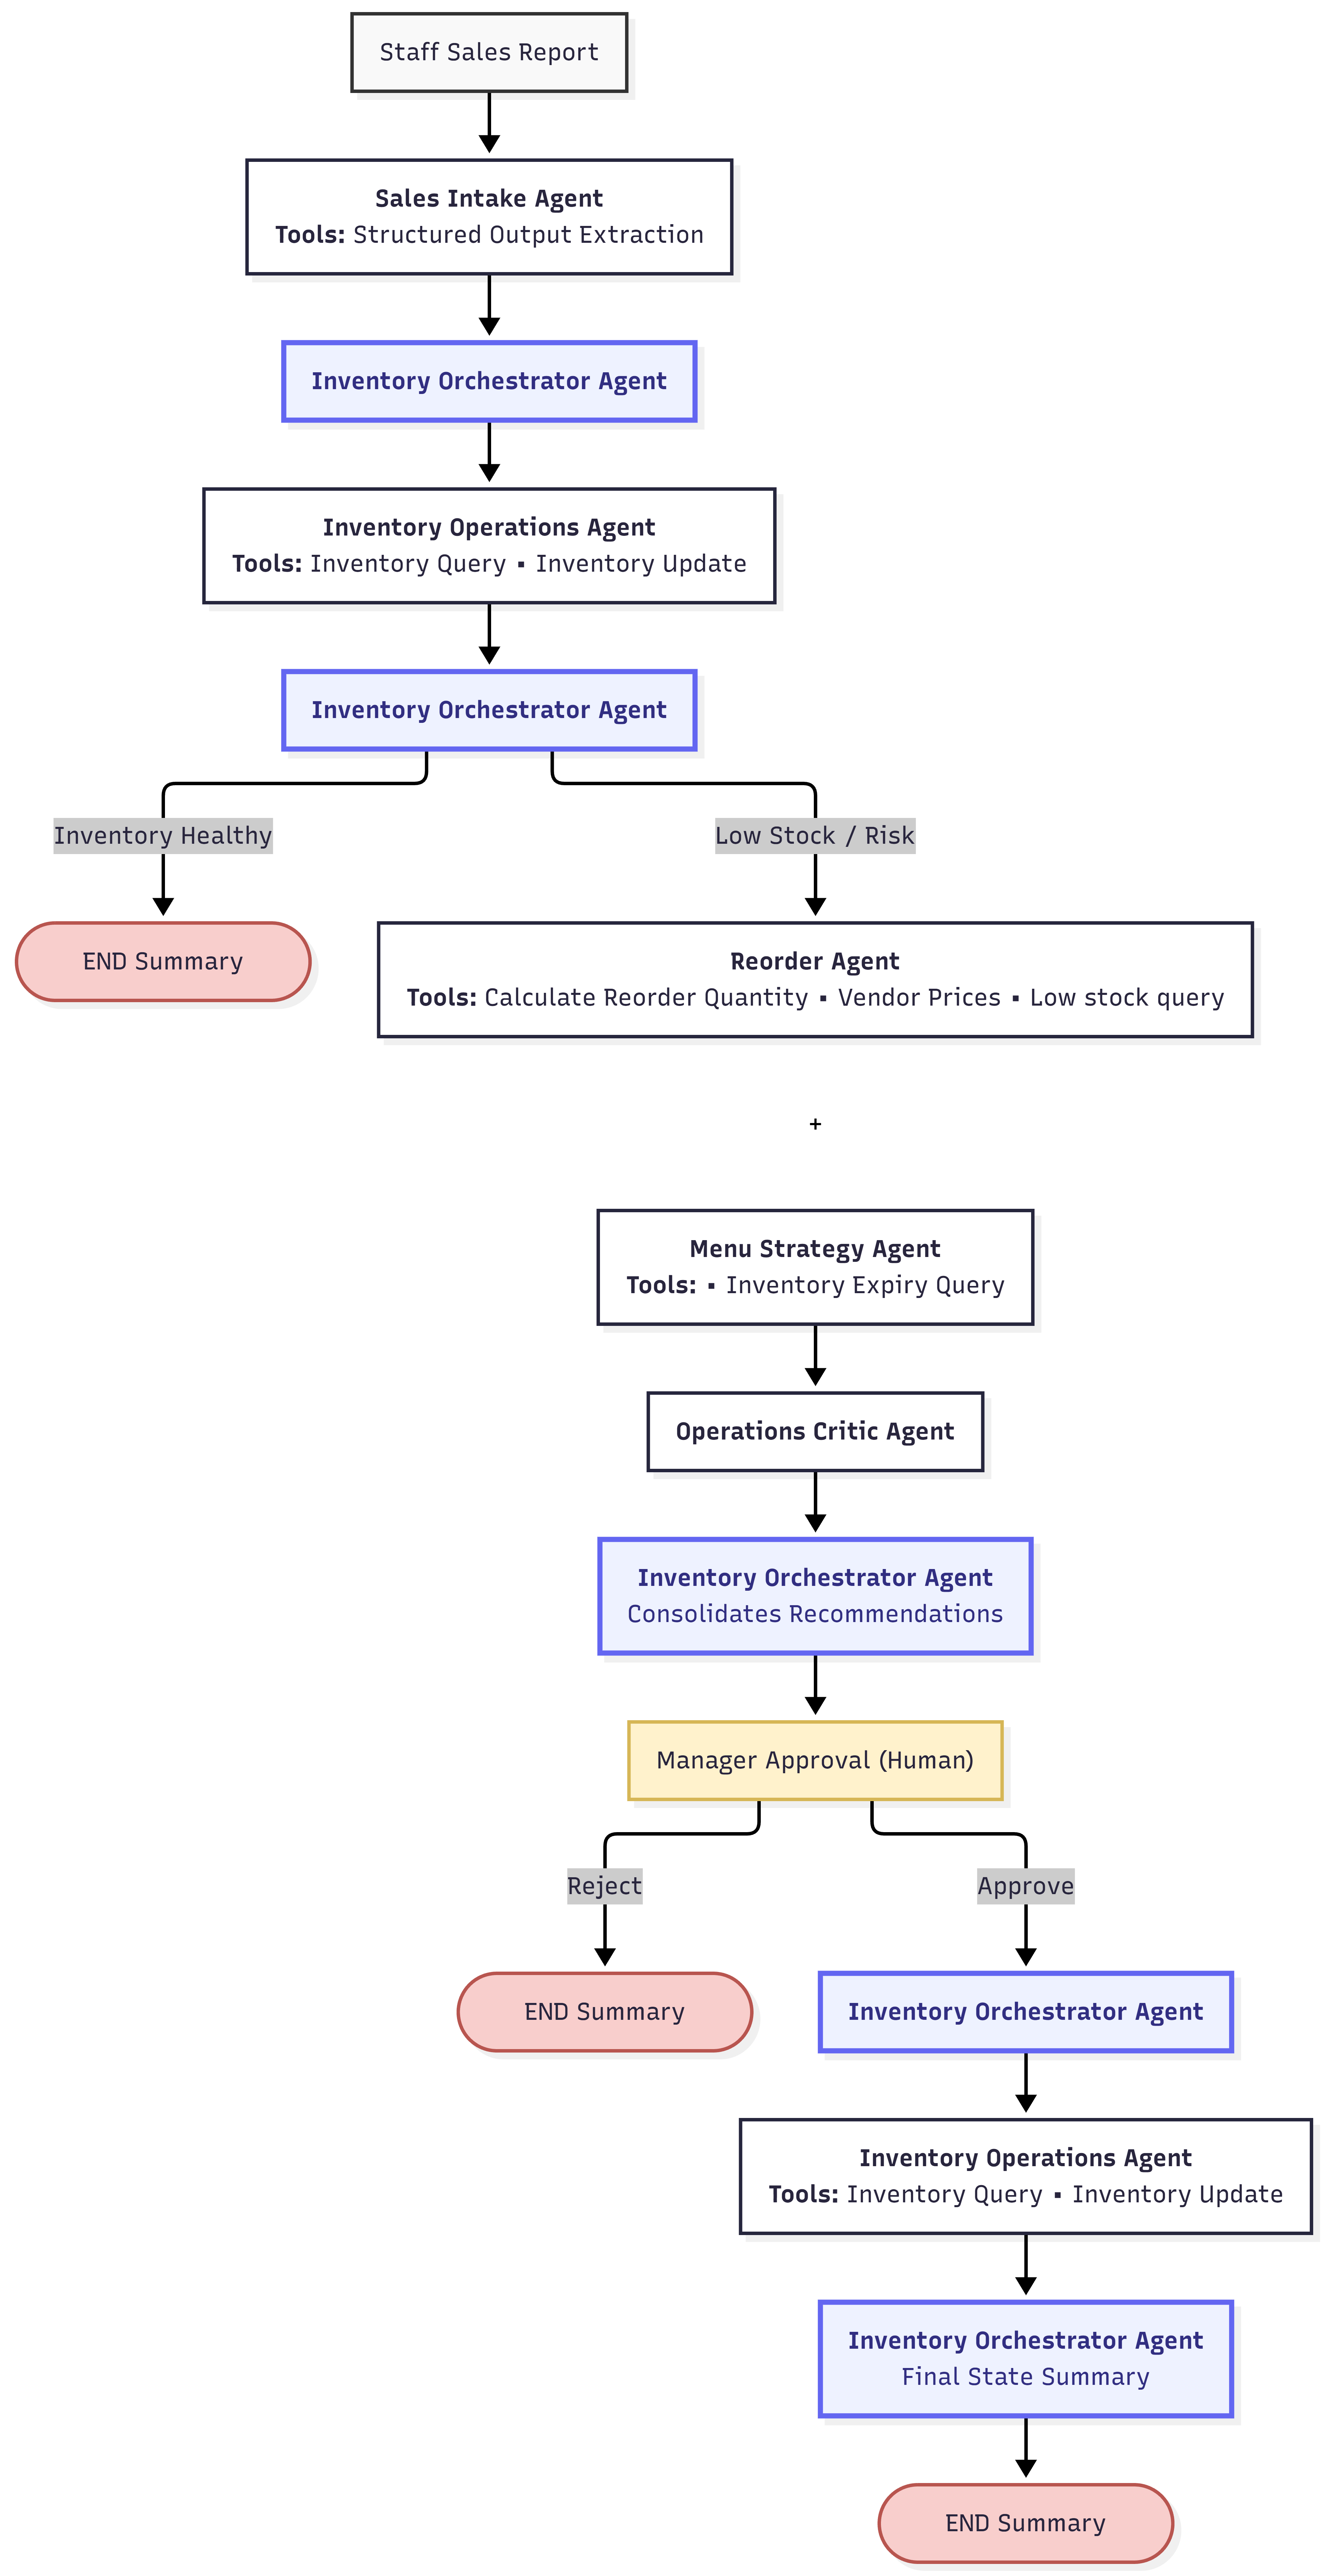

In [ ]:
"""Workflow Architecture Design"""
from IPython.display import Image, display

display(Image(filename='workflow_image/multi_agent_system.png', width=700, height=300))

### Import Dependencies and Setup Keys

In [ ]:
# Set the key for this active VS Code kernel session
import os
os.environ["GOOGLE_API_KEY"] = ""
# This truncates the Pydantic Banner in the Terminal
os.environ["PYDANTIC_AI_NO_BANNER"] = "1"

# Access it anywhere else in the notebook
api_key = os.environ.get("GOOGLE_API_KEY")


In [ ]:
# Local Imports (Libs)
from libs.manager_input import (
    get_sample_manager_report,
)

from libs.agents import (
    SalesIntakeAgent,
    InventoryOrchestrator
)

from libs.models import (
    SalesReport,
)

from libs.state import (
    WorkflowState
)

from libs.token_tracker import (
    TokenTracker,
)

from libs.evaluation import(
    test_sales_intake_agent,
    test_inventory_operations_agent,
    test_reorder_agent,
    test_menu_strategy_agent,
    test_critic_agent,
    test_full_workflow_approved,
    test_workflow_retry_path,
    test_invalid_manager_input,
    test_workflow_with_empty_sales_report,
)


# Configure our logging to print in the notebook
from libs.logging_config import configure_logging

configure_logging()


### Run Our Agentic Workflow Integration
- We will get our simulated Manager Input
- Invoke our Sales Intake Agent to produce a Sales Report (First Phase of our Workflow)
- Then we will start our workflow (Semi-Autonomous Human in the Loop)
- The system will provide a reorder and menu recommendation for the Manager to approve or deny with Feedback.
- With the manager input the agentic system will complete the workflow.
- We will run it in different cells to demonstrate the stages then run the entire workflow after.

In [14]:
# Get a sample Manager Input
sales_text = (
    get_sample_manager_report()
)

print(sales_text)


    Busy lunch service.

    Sold:
    - 5 Margherita Pizzas
    - 10 Pesto Penne
    - 10 Vegetarian Pizzas
    


In [15]:
# Setup Token Tracker and generate the first Sales Report from the Sales Agent
token_tracker = TokenTracker()

sales_agent = SalesIntakeAgent(
    token_tracker
)

sales_report = await sales_agent.execute(
    sales_text
)

sales_report

17:30:27 | INFO | libs.llm | Creating SalesIntakAgent with model: google:gemini-3.5-flash
17:30:27 | INFO | SalesIntakeAgent | Processing manager sales report.
17:30:30 | INFO | httpx2 | HTTP Request: POST https://generativelanguage.googleapis.com/v1beta/models/gemini-3.5-flash:generateContent "HTTP/1.1 200 OK"
17:30:30 | INFO | SalesIntakeAgent | 
=== TOKEN USAGE SUMMARY ===
Requests          : 1
Request Tokens    : 359
Response Tokens   : 360
Reasoning Tokens  : 302
Total Tokens      : 719
Estimated Cost    : $0.00162



SalesReport(sales=[SalesItem(menu_item='Margherita Pizza', quantity=5), SalesItem(menu_item='Pesto Penne', quantity=10), SalesItem(menu_item='Vegetarian Pizza', quantity=10)])

In [16]:
#Intialize State
state = WorkflowState(
    sales_report=sales_report
)

# Intitialize our maine orchestrator agent
orchestrator = InventoryOrchestrator(
    token_tracker
)

response = await orchestrator.run(
    state
)

17:31:42 | INFO | libs.llm | Creating ReorderAgent with model: google:gemini-3.5-flash
17:31:42 | INFO | libs.llm | Creating MenuStrategyAgent with model: google:gemini-3.5-flash
17:31:42 | INFO | libs.llm | Creating CriticAgent with model: google:gemini-3.5-flash
17:31:42 | INFO | InventoryOrchestrator | Starting inventory workflow.
17:31:42 | INFO | libs.state_machine | [StateMachine] Starting: __entry__
17:31:42 | INFO | InventoryOperationsAgent | Starting agent: InventoryOperationsAgent
17:31:42 | INFO | InventoryOperationsAgent | Applied 13 inventory updates.
17:31:42 | INFO | InventoryOperationsAgent | Completed agent: InventoryOperationsAgent in 0.02s
17:31:42 | INFO | libs.state_machine | [StateMachine] Executing step: INVENTORY_ANALYSIS
17:31:42 | INFO | ReorderAgent | Starting agent: ReorderAgent
17:31:47 | INFO | httpx2 | HTTP Request: POST https://generativelanguage.googleapis.com/v1beta/models/gemini-3.5-flash:generateContent "HTTP/1.1 200 OK"
17:31:47 | INFO | ReorderAgen

In [17]:
print(response.summary)

Workflow completed successfully. Executed 2 actions. Agents Invoked: InventoryOperationsAgent, ReorderAgent, MenuStrategyAgent, CriticAgent.


In [18]:
response.metrics

WorkflowMetrics(workflow_id='eb3ce873-222c-4e03-ac30-7a71da73ae2a', agents_invoked=['InventoryOperationsAgent', 'ReorderAgent', 'MenuStrategyAgent', 'CriticAgent'], execution_time_seconds=15.383283999981359, token_usage=TokenUsage(request_tokens=2255, response_tokens=2655, total_tokens=4910, requests=4, reasoning_tokens=2122, estimated_cost=0.011647500000000002))

### System Evaluation and Testing

**Individual Agent Testing**

In [19]:
# Sales Intake Agent Test
sales_report = await (
    test_sales_intake_agent()
)


=== SALES INTAKE AGENT TEST ===
17:32:29 | INFO | libs.llm | Creating SalesIntakAgent with model: google:gemini-3.5-flash

INPUT REPORT:

    Today we sold:
    - 4 Margherita Pizzas
    - 3 Alfredo Pastas
    - 6 Spaghetti Bolognese
    
17:32:29 | INFO | SalesIntakeAgent | Processing manager sales report.
17:32:31 | INFO | httpx2 | HTTP Request: POST https://generativelanguage.googleapis.com/v1beta/models/gemini-3.5-flash:generateContent "HTTP/1.1 200 OK"
17:32:31 | INFO | SalesIntakeAgent | 
=== TOKEN USAGE SUMMARY ===
Requests          : 1
Request Tokens    : 352
Response Tokens   : 294
Reasoning Tokens  : 238
Total Tokens      : 646
Estimated Cost    : $0.00137


STRUCTURED OUTPUT:
sales=[SalesItem(menu_item='Margherita Pizza', quantity=4), SalesItem(menu_item='Alfredo Pasta', quantity=3), SalesItem(menu_item='Spaghetti Bolognese', quantity=6)]

 TEST PASSED


In [20]:
# Inventory Ops Agent Test
assessment = await (
    test_inventory_operations_agent()
)


=== INVENTORY OPERATIONS AGENT TEST ===
>>> Dropped table: inventory
>>> Dropped table: recipes
>>> Dropped table: vendor_prices
>>> Dropped table: menu_items
>>> Dropped table: workflow_runs
>>>> Database cleaned.
>>> Created table: inventory
>>> Created table: recipes
>>> Created table: vendor_prices
>>> Created table: menu_items
>>> Created table: workflow_runs
>>>> All tables created successfully.
>>>> Database reset complete.
<<<< Seeded 14 inventory records.
<<<< Seeded 24 recipe records.
<<<< Seeded 28 vendor pricing records.
<<<< Seeded 6 menu items.
>>>>> <<<<<< Database successfully seeded.
Test Environment reset and seeded successfully.

INPUT SALES REPORT:
sales=[SalesItem(menu_item='Margherita Pizza', quantity=4), SalesItem(menu_item='Alfredo Pasta', quantity=3), SalesItem(menu_item='Spaghetti Bolognese', quantity=6)]
17:32:37 | INFO | InventoryOperationsAgent | Starting agent: InventoryOperationsAgent
17:32:38 | INFO | InventoryOperationsAgent | Applied 11 inventory upda

In [21]:
reorder = await (
    test_reorder_agent()
)


=== REORDER AGENT TEST ===
17:32:47 | INFO | libs.llm | Creating ReorderAgent with model: google:gemini-3.5-flash

INPUT INVENTORY ASSESSMENT:
inventory_healthy=False low_stock_items=['Basil', 'Mozzarella', 'Pesto Sauce'] expiry_risk_items=[] summary='Several ingredients are below their reorder thresholds.'
17:32:48 | INFO | ReorderAgent | Starting agent: ReorderAgent
17:32:52 | INFO | httpx2 | HTTP Request: POST https://generativelanguage.googleapis.com/v1beta/models/gemini-3.5-flash:generateContent "HTTP/1.1 200 OK"
17:32:56 | INFO | httpx2 | HTTP Request: POST https://generativelanguage.googleapis.com/v1beta/models/gemini-3.5-flash:generateContent "HTTP/1.1 200 OK"
17:32:59 | INFO | httpx2 | HTTP Request: POST https://generativelanguage.googleapis.com/v1beta/models/gemini-3.5-flash:generateContent "HTTP/1.1 200 OK"
17:32:59 | INFO | ReorderAgent | 
=== TOKEN USAGE SUMMARY ===
Requests          : 3
Request Tokens    : 1431
Response Tokens   : 1983
Reasoning Tokens  : 1608
Total Toke

In [22]:
menu_rec = await (
    test_menu_strategy_agent()
)


=== MENU STRATEGY AGENT TEST ===
17:33:06 | INFO | libs.llm | Creating MenuStrategyAgent with model: google:gemini-3.5-flash

INPUT INVENTORY ASSESSMENT:
inventory_healthy=False low_stock_items=[] expiry_risk_items=['Basil', 'Mushrooms', 'Pesto Sauce'] summary='Several ingredients are approaching their expiry dates.'
17:33:06 | INFO | MenuStrategyAgent | Starting agent: MenuStrategyAgent
17:33:11 | INFO | httpx2 | HTTP Request: POST https://generativelanguage.googleapis.com/v1beta/models/gemini-3.5-flash:generateContent "HTTP/1.1 200 OK"
17:33:11 | INFO | MenuStrategyAgent | 
=== TOKEN USAGE SUMMARY ===
Requests          : 1
Request Tokens    : 358
Response Tokens   : 765
Reasoning Tokens  : 601
Total Tokens      : 1123
Estimated Cost    : $0.00314

17:33:11 | INFO | MenuStrategyAgent | Completed agent: MenuStrategyAgent in 4.83s

MENU RECOMMENDATION:

        Special Name:
        Funghi al Pesto con Basilico Fresco

        Ingredients Used:
        Basil, Mushrooms, Pesto Sauce

  

In [23]:
review = await (
    test_critic_agent()
)


=== CRITIC AGENT TEST ===
17:33:15 | INFO | libs.llm | Creating CriticAgent with model: google:gemini-3.5-flash

INPUT RECOMMENDATIONS:
[ReorderRecommendation(ingredient_name='Basil', reorder_quantity=6.0, recommended_vendor='Fresh Foods Wholesale', total_cost=32.83, justification='Current stock is critically below reorder threshold.'), ReorderRecommendation(ingredient_name='Mozzarella', reorder_quantity=19.0, recommended_vendor='Fresh Foods Wholesale', total_cost=155.13, justification='Current stock is critically low and requires rapid replenishment.')]
[MenuRecommendation(special_name='Rustic Pesto Mushroom & Fresh Basil Special', ingredients_used=['Basil', 'Mushrooms', 'Pesto Sauce'], reasoning='Uses multiple ingredients nearing expiry and reduces waste.')]
17:33:15 | INFO | CriticAgent | Starting agent: CriticAgent
17:33:23 | INFO | httpx2 | HTTP Request: POST https://generativelanguage.googleapis.com/v1beta/models/gemini-3.5-flash:generateContent "HTTP/1.1 200 OK"
17:33:23 | INFO

In [24]:
invalid_input_test = await (
    test_invalid_manager_input()
)


=== INVALID MANAGER INPUT TEST ===
17:33:27 | INFO | libs.llm | Creating SalesIntakAgent with model: google:gemini-3.5-flash

INPUT REPORT:

    Yesterday was busy.

    Sold lots of food.

    Need more cheese soon.

    Everything went well.
    
17:33:27 | INFO | SalesIntakeAgent | Processing manager sales report.
17:33:29 | INFO | httpx2 | HTTP Request: POST https://generativelanguage.googleapis.com/v1beta/models/gemini-3.5-flash:generateContent "HTTP/1.1 200 OK"
17:33:29 | INFO | SalesIntakeAgent | 
=== TOKEN USAGE SUMMARY ===
Requests          : 1
Request Tokens    : 348
Response Tokens   : 175
Reasoning Tokens  : 162
Total Tokens      : 523
Estimated Cost    : $0.00092


STRUCTURED OUTPUT:
sales=[]

 OBSERVATION:
Agent was unable to identify any structured sales information from the manager input and returned an empty SalesReport.


### Full Workflow Test: Main orchestrator agent test

In [25]:
# First we can test the workflow in the case where the Manager approves the recommendations
approved = await (
    test_full_workflow_approved()
)


=== FULL WORKFLOW TEST (APPROVED) ===
>>> Dropped table: inventory
>>> Dropped table: recipes
>>> Dropped table: vendor_prices
>>> Dropped table: menu_items
>>> Dropped table: workflow_runs
>>>> Database cleaned.
>>> Created table: inventory
>>> Created table: recipes
>>> Created table: vendor_prices
>>> Created table: menu_items
>>> Created table: workflow_runs
>>>> All tables created successfully.
>>>> Database reset complete.
<<<< Seeded 14 inventory records.
<<<< Seeded 24 recipe records.
<<<< Seeded 28 vendor pricing records.
<<<< Seeded 6 menu items.
>>>>> <<<<<< Database successfully seeded.
Test Environment reset and seeded successfully.
17:33:44 | INFO | libs.llm | Creating SalesIntakAgent with model: google:gemini-3.5-flash
17:33:44 | INFO | libs.llm | Creating ReorderAgent with model: google:gemini-3.5-flash
17:33:44 | INFO | libs.llm | Creating MenuStrategyAgent with model: google:gemini-3.5-flash
17:33:44 | INFO | libs.llm | Creating CriticAgent with model: google:gemini-

In [26]:
retry_test = await (
    test_workflow_retry_path()
)


=== WORKFLOW RETRY TEST ===
>>> Dropped table: inventory
>>> Dropped table: recipes
>>> Dropped table: vendor_prices
>>> Dropped table: menu_items
>>> Dropped table: workflow_runs
>>>> Database cleaned.
>>> Created table: inventory
>>> Created table: recipes
>>> Created table: vendor_prices
>>> Created table: menu_items
>>> Created table: workflow_runs
>>>> All tables created successfully.
>>>> Database reset complete.
<<<< Seeded 14 inventory records.
<<<< Seeded 24 recipe records.
<<<< Seeded 28 vendor pricing records.
<<<< Seeded 6 menu items.
>>>>> <<<<<< Database successfully seeded.
Test Environment reset and seeded successfully.
17:34:15 | INFO | libs.llm | Creating SalesIntakAgent with model: google:gemini-3.5-flash
17:34:15 | INFO | libs.llm | Creating ReorderAgent with model: google:gemini-3.5-flash
17:34:15 | INFO | libs.llm | Creating MenuStrategyAgent with model: google:gemini-3.5-flash
17:34:15 | INFO | libs.llm | Creating CriticAgent with model: google:gemini-3.5-flash


In [27]:
# Failure Case
empty_sales_test = await (
    test_workflow_with_empty_sales_report()
)


=== EMPTY SALES REPORT WORKFLOW TEST ===
>>> Dropped table: inventory
>>> Dropped table: recipes
>>> Dropped table: vendor_prices
>>> Dropped table: menu_items
>>> Dropped table: workflow_runs
>>>> Database cleaned.
>>> Created table: inventory
>>> Created table: recipes
>>> Created table: vendor_prices
>>> Created table: menu_items
>>> Created table: workflow_runs
>>>> All tables created successfully.
>>>> Database reset complete.
<<<< Seeded 14 inventory records.
<<<< Seeded 24 recipe records.
<<<< Seeded 28 vendor pricing records.
<<<< Seeded 6 menu items.
>>>>> <<<<<< Database successfully seeded.
Test Environment reset and seeded successfully.
17:35:05 | INFO | libs.llm | Creating ReorderAgent with model: google:gemini-3.5-flash
17:35:05 | INFO | libs.llm | Creating MenuStrategyAgent with model: google:gemini-3.5-flash
17:35:05 | INFO | libs.llm | Creating CriticAgent with model: google:gemini-3.5-flash

INPUT SALES REPORT:
sales=[]
17:35:05 | INFO | InventoryOrchestrator | Start

**Notes on How the Agent Reasons Through Decisions**

- The workflow uses a state driven multi-agent architecture, where each agent receives relevant information from the shared WorkflowState and contributes a specialized decision.
- The Inventory Operations Agent analyzes sales data, updates inventory levels, and identifies low-stock and expiry-risk ingredients.
- The Reorder Agent evaluates inventory shortages, vendor pricing, and delivery times to balance cost efficiency with stock-out risk when selecting suppliers.
- The Menu Strategy Agent identifies ingredients nearing expiration and recommends menu specials that help reduce food waste.
- The Critic Agent independently reviews reorder and menu recommendations, providing an approval decision, confidence score, and justification before recommendations proceed to management review.
- The workflow includes a human-in-the-loop approval stage, allowing a manager to approve or reject recommendations before inventory updates are executed.
- Reasoning outputs are provided throughout the logs for review and evaluation, llm did a good job reasoning through problems set out.

**Limitation, Failure Case, or Unexpected Behavior**

*Failure Case*

During testing, an invalid manager report resulted in an empty SalesReport. The workflow did not fail and continued operating using the current inventory state. While this prevented system failure, it also allowed recommendations to be generated without any actual sales activity being recorded. This behavior demonstrates a possible failure in input validation at the workflow entry point. This will need to be corrected in future project updates

*Observed Limitation*

Manager rejection causes the workflow to regenerate recommendations by rerunning the Reorder, Menu Strategy, and Critic agents.
While this improves oversight and control, it increases execution time and token consumption. During testing, a rejection and retry scenario increased total token usage by approximitely 40-50%, nearly doubling workflow cost and latency.

*Unexpected Behavior*

Repeated executions may generate slightly different menu recommendations and justifications even when inventory conditions remain unchanged.
The recommendations remain valid, but LLM-generated wording and dish naming can vary between runs due to probabilistic model behavior.

### Summary Report

This project implemented a semi-autonomous multi-agent workflow for restaurant inventory management, supplier planning, and food waste reduction. The system uses a shared workflow state, a custom state machine orchestrator, and multiple specialized agents to transform natural language sales reports into inventory updates, procurement recommendations, and menu optimization strategies while maintaining human oversight through a manager approval stage.

During execution, the system successfully demonstrated structured data extraction, inventory analysis, supplier evaluation, menu recommendation generation, independent recommendation review, and conditional workflow routing. Testing confirmed that agents could operate independently using only the workflow state relevant to their responsibilities, while full workflow evaluations validated orchestration, retry behavior, and human-in-the-loop decision making.

Several challenges were encountered during development, including database path configuration issues, logging configuration within Jupyter notebooks, and balancing recommendation quality with deterministic business rules. These issues were resolved through improved database management, centralized logging, and additional workflow safeguards.

A key limitation observed during testing was that an empty SalesReport allowed the workflow to continue using existing inventory data, resulting in recommendations being generated without any recorded sales activity. Future enhancements should include stricter input validation and workflow entry-point checks to ensure meaningful sales data is present before inventory analysis begins. The project also demonstrated that manager approval retries improve oversight but increase execution time, token consumption, and overall workflow cost.
